# 03 – Hypothesis Tests

**Goal:** Run the statistical tests defined in the README (H1–H6) to check whether the draws are consistent with a fair lottery.

**Input:** `data/processed/lotto_current_format.csv`

**Significance level:** α = 0.05, fixed in the README before running any test.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

ALPHA = 0.05  # fixed in the README before testing

df = pd.read_csv("../data/processed/lotto_current_format.csv", parse_dates=["date"])
num_cols = ["n1", "n2", "n3", "n4", "n5", "n6"]
n_draws = len(df)

print(n_draws)

1744


## H1 – Are the main numbers uniform?

- **H0:** every number from 1 to 37 has the same probability (6/37) of appearing in a draw.
- **H1:** at least one number has a different probability.
- **Method:** chi-square goodness-of-fit test. For each number it compares the observed count with the expected count, sums the squared differences (scaled by the expected count), and asks how likely such a large total would be if the lottery were fair.

In [2]:
observed = df[num_cols].stack().value_counts().sort_index()
expected = n_draws * 6 / 37

chi2, p_value = stats.chisquare(observed, f_exp=np.full(37, expected))

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {len(observed) - 1}")
print(f"p-value: {p_value:.3f}")
print("Reject H0" if p_value < ALPHA else "Fail to reject H0")

Chi-square statistic: 28.72
Degrees of freedom: 36
p-value: 0.800
Fail to reject H0


**Result**
- Chi-square statistic = 28.72 with 36 degrees of freedom, p-value = 0.80.
- Since p > 0.05, I fail to reject H0: there is no evidence that the main numbers are drawn with unequal probabilities.
- This does not prove that the lottery is fair. It only means that, with 1,744 draws, the observed differences are fully consistent with random variation.
- Caveat: the chi-square test treats the counts as if every drawn number were independent. In reality the six numbers of a draw are drawn without replacement, so the reference distribution is only approximate. The next step checks the result with a Monte Carlo simulation.

### H1 – Monte Carlo check
The classic chi-square test assumes that every drawn number is independent. In a real draw, the six numbers are drawn without replacement, which slightly reduces the random variation of the counts. To avoid relying on this approximation, I simulate a fair lottery many times (same number of draws, 6 numbers out of 37 without repetition), compute the chi-square statistic of each simulated lottery, and check where the observed value falls in this distribution.

In [4]:
rng = np.random.default_rng(42)  # fixed seed so the result is reproducible
n_sims = 10_000
sim_chi2 = np.empty(n_sims)

for i in range(n_sims):
    # give each of the 37 numbers a random score in every draw;
    # the 6 numbers with the lowest scores are the drawn ones
    drawn = rng.random((n_draws, 37)).argpartition(6, axis=1)[:, :6]
    counts = np.bincount(drawn.ravel(), minlength=37)
    sim_chi2[i] = ((counts - expected) ** 2 / expected).sum()

# +1 in both parts avoids reporting an impossible p-value of exactly 0
p_mc = (np.sum(sim_chi2 >= chi2) + 1) / (n_sims + 1)

print(f"Observed chi-square: {chi2:.2f}")
print(f"Mean of simulated chi-square: {sim_chi2.mean():.2f} (classic chi-square mean: 36)")
print(f"95th percentile of simulated chi-square: {np.percentile(sim_chi2, 95):.2f}")
print(f"Monte Carlo p-value: {p_mc:.3f}")

Observed chi-square: 28.72
Mean of simulated chi-square: 31.05 (classic chi-square mean: 36)
95th percentile of simulated chi-square: 43.83
Monte Carlo p-value: 0.601


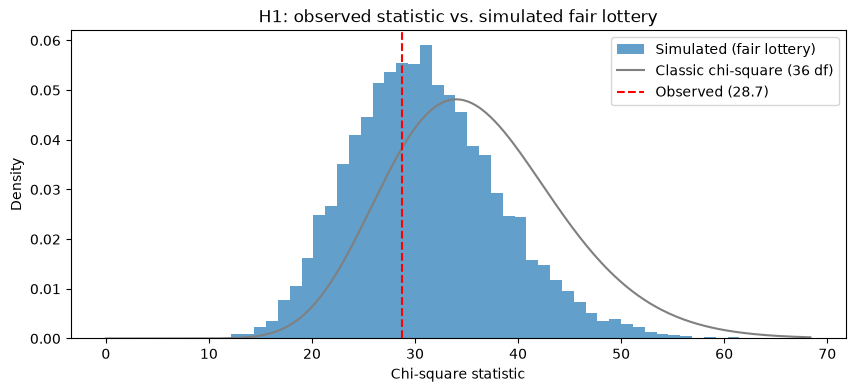

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(sim_chi2, bins=50, density=True, alpha=0.7, label="Simulated (fair lottery)")
x = np.linspace(0, sim_chi2.max(), 300)
ax.plot(x, stats.chi2.pdf(x, 36), color="gray", label="Classic chi-square (36 df)")
ax.axvline(chi2, color="red", linestyle="--", label=f"Observed ({chi2:.1f})")

ax.set_xlabel("Chi-square statistic")
ax.set_ylabel("Density")
ax.set_title("H1: observed statistic vs. simulated fair lottery")
ax.legend()

plt.show()

**Result**
- The simulated chi-square values average 31.05, not 36 as the classic distribution assumes. Drawing numbers without replacement reduces the variation in the counts, which is why the classic test is slightly conservative.
- The observed statistic (28.72) lies in the middle of the simulated distribution. The Monte Carlo p-value is 0.60, well above α = 0.05.
- **Conclusion for H1:** both the classic test (p = 0.80) and the simulation (p = 0.60) fail to reject H0. There is no evidence that the 37 main numbers are drawn with unequal probabilities.

## H2 – Is the strong number uniform?

- **H0:** every strong number from 1 to 7 has the same probability (1/7) in a draw.
- **H1:** at least one value has a different probability.
- **Method:** chi-square goodness-of-fit test. Unlike the main numbers, exactly one strong number is drawn per draw, so the counts follow the multinomial model that the classic test assumes, and no simulation is needed.

In [6]:
strong_observed = df["strong"].value_counts().sort_index()
strong_expected = n_draws / 7

chi2_strong, p_strong = stats.chisquare(strong_observed, f_exp=np.full(7, strong_expected))

print(f"Chi-square statistic: {chi2_strong:.2f}")
print(f"Degrees of freedom: {len(strong_observed) - 1}")
print(f"p-value: {p_strong:.3f}")
print("Reject H0" if p_strong < ALPHA else "Fail to reject H0")

Chi-square statistic: 2.97
Degrees of freedom: 6
p-value: 0.813
Fail to reject H0


**Result**
- Chi-square statistic = 2.97 with 6 degrees of freedom, p-value = 0.81.
- Since p > 0.05, I fail to reject H0: the observed strong number counts (236 to 264, expected 249) are fully consistent with a uniform draw.
- **Conclusion for H2:** no evidence that any strong number is favored or avoided.

## H3 – Are consecutive draws independent?

- **H0:** draws have no memory. The number of values shared by two consecutive draws follows the hypergeometric distribution (mean 6 × 6 / 37 ≈ 0.97).
- **H1:** the distribution of shared numbers differs from the hypergeometric one.
- **Method:** chi-square goodness-of-fit test on the number of shared values (0, 1, 2, 3+), checked with a Monte Carlo simulation. Draws with 3 or more shared numbers are merged into one group because the expected counts for 4, 5 and 6 shared numbers are too small for the test.
- **Note:** neighboring pairs share a draw (draw t is part of the pairs t-1→t and t→t+1), so the pairs are not fully independent. The simulation reproduces this structure and gives the more reliable p-value.

In [7]:
draws = df[num_cols].to_numpy()

# overlap = how many numbers a draw shares with the previous draw (data is sorted by date)
overlap = np.array([len(set(draws[i]) & set(draws[i - 1])) for i in range(1, n_draws)])
n_pairs = len(overlap)

# if draws are independent, the overlap is hypergeometric:
# 37 numbers in total, 6 of them "marked" (previous draw), 6 drawn (current draw)
overlap_probs = stats.hypergeom.pmf(range(7), 37, 6, 6)

overlap_table = pd.DataFrame({
    "observed": np.bincount(overlap, minlength=7),
    "expected": (overlap_probs * n_pairs).round(1),
})
overlap_table.index.name = "shared numbers"

print(f"Pairs of consecutive draws: {n_pairs}")
print(f"Mean overlap: observed {overlap.mean():.3f}, expected {6 * 6 / 37:.3f}")
overlap_table

Pairs of consecutive draws: 1743
Mean overlap: observed 0.992, expected 0.973


,observed,expected
shared numbers,,
0,515,552.0
1,819,764.3
2,325,353.9
3,76,67.4
4,8,5.2
5,0,0.1
6,0,0.0


In [8]:
# merge 3+ shared numbers into one group (expected counts for 4, 5, 6 are too small)
def group_overlap(values):
    return np.append(values[:3], values[3:].sum())

obs_grouped = group_overlap(np.bincount(overlap, minlength=7))
exp_grouped = group_overlap(overlap_probs) * n_pairs

chi2_overlap, p_overlap = stats.chisquare(obs_grouped, f_exp=exp_grouped)

print(f"Chi-square statistic: {chi2_overlap:.2f}")
print(f"Degrees of freedom: {len(obs_grouped) - 1}")
print(f"p-value: {p_overlap:.3f}")
print("Reject H0" if p_overlap < ALPHA else "Fail to reject H0")

Chi-square statistic: 10.48
Degrees of freedom: 3
p-value: 0.015
Reject H0


In [9]:
rng = np.random.default_rng(42)
n_sims = 10_000
sim_chi2_overlap = np.empty(n_sims)
draw_idx = np.arange(n_draws)[:, None]

for i in range(n_sims):
    drawn = rng.random((n_draws, 37)).argpartition(6, axis=1)[:, :6]
    drawn_flags = np.zeros((n_draws, 37), dtype=bool)
    drawn_flags[draw_idx, drawn] = True

    # numbers shared by each draw and the previous one
    sim_overlap = (drawn_flags[1:] & drawn_flags[:-1]).sum(axis=1)
    sim_grouped = group_overlap(np.bincount(sim_overlap, minlength=7))
    sim_chi2_overlap[i] = ((sim_grouped - exp_grouped) ** 2 / exp_grouped).sum()

p_overlap_mc = (np.sum(sim_chi2_overlap >= chi2_overlap) + 1) / (n_sims + 1)

print(f"Observed chi-square: {chi2_overlap:.2f}")
print(f"Mean of simulated chi-square: {sim_chi2_overlap.mean():.2f}")
print(f"95th percentile of simulated chi-square: {np.percentile(sim_chi2_overlap, 95):.2f}")
print(f"Monte Carlo p-value: {p_overlap_mc:.3f}")

Observed chi-square: 10.48
Mean of simulated chi-square: 3.00
95th percentile of simulated chi-square: 7.75
Monte Carlo p-value: 0.016


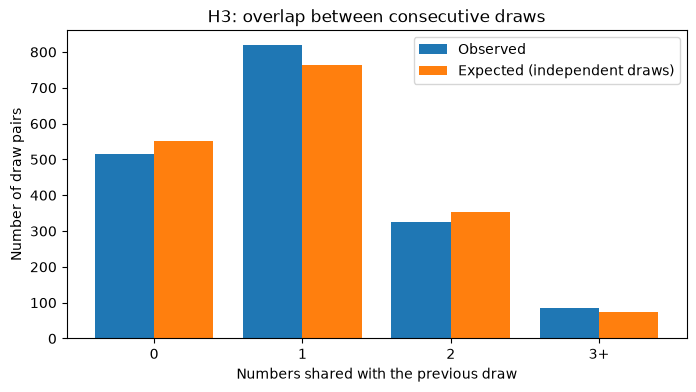

In [10]:
import matplotlib.pyplot as plt

x = np.arange(4)
width = 0.4

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(x - width / 2, obs_grouped, width, label="Observed")
ax.bar(x + width / 2, exp_grouped, width, label="Expected (independent draws)")

ax.set_xticks(x)
ax.set_xticklabels(["0", "1", "2", "3+"])
ax.set_xlabel("Numbers shared with the previous draw")
ax.set_ylabel("Number of draw pairs")
ax.set_title("H3: overlap between consecutive draws")
ax.legend()

plt.show()

**Result**
- Across 1,743 pairs of consecutive draws, the mean overlap is 0.992 vs. 0.973 expected, so the average is almost exactly what independence predicts.
- The shape of the distribution differs slightly: fewer pairs share 0 numbers (515 vs. 552 expected) or 2 numbers (325 vs. 354), while more pairs share exactly 1 number (819 vs. 764) or 3+ numbers (84 vs. 73).
- Chi-square statistic = 10.48 with 3 degrees of freedom, p = 0.015. The Monte Carlo p-value is 0.016, so the classic test is reliable here. At the unadjusted α = 0.05, H0 is rejected.
- **This result should be read with caution.** H3 is one of six tests planned in the README. With a multiple-comparison correction (e.g. Bonferroni threshold 0.05 / 6 ≈ 0.008, or Holm), p = 0.015 would no longer be significant. The final verdict is given after all tests are done and after a stability check on this result.

### H3 – Stability check
To see whether the deviation is a stable feature or a one-off fluctuation, I repeat the same test separately on the first and on the second half of the period. This check was added after seeing the H3 result, so it is exploratory and not part of the original plan.

In [11]:
def overlap_test(values):
    # same chi-square test as above, applied to any subset of overlaps
    obs = group_overlap(np.bincount(values, minlength=7))
    exp = group_overlap(overlap_probs) * len(values)
    return stats.chisquare(obs, f_exp=exp)

half = n_pairs // 2
print(f"Split date: {df['date'].iloc[half].date()}")

for name, part in [("First half", overlap[:half]), ("Second half", overlap[half:])]:
    chi2_part, p_part = overlap_test(part)
    print(f"{name}: pairs = {len(part)}, chi-square = {chi2_part:.2f}, p-value = {p_part:.3f}")

Split date: 2019-02-12
First half: pairs = 871, chi-square = 11.05, p-value = 0.011
Second half: pairs = 872, chi-square = 4.80, p-value = 0.187


**Result**
- First half (up to 2019-02-12): chi-square = 11.05, p = 0.011.
- Second half: chi-square = 4.80, p = 0.187.
- The deviation is clearly visible in the first half but not in the second. Each half has only half of the data and therefore less statistical power, so the second result does not prove that the effect is absent. Still, an effect that is real and stable would normally show up in both periods.
- **Conclusion for H3:** the unadjusted p-value of 0.015 is not strong enough to claim that draws have memory. The deviation is not stable over time and does not survive a multiple-comparison correction. I treat it as a weak, unconfirmed signal consistent with chance.

## H4 – Do "hot" numbers stay hot?

- **H0:** the frequency ranking of the 37 numbers in one year is unrelated to the ranking in the next year (Spearman correlation = 0).
- **H1:** the rankings are related (positive correlation means "hot" numbers tend to stay hot, negative means they tend to cool down).
- **Method:** Spearman rank correlation between each pair of consecutive calendar years, averaged over all pairs. The p-value comes from a Monte Carlo simulation of a fair lottery with the same number of draws per year, because neighboring pairs share a year and are therefore not independent. The test is two-sided.
- **Note:** 2011 (from March 5) and 2026 (until October 20) are partial years with fewer draws. Ranks are used instead of raw counts, so partial years do not distort the comparison, but they are noisier.

In [12]:
df["year"] = df["date"].dt.year
years = sorted(df["year"].unique())

# rows = numbers 1-37, columns = years
yearly_counts = pd.DataFrame({
    year: df.loc[df["year"] == year, num_cols].stack().value_counts().reindex(range(1, 38), fill_value=0)
    for year in years
})

# Spearman correlation between each year and the next one
year_pairs = list(zip(years[:-1], years[1:]))
rhos = [stats.spearmanr(yearly_counts[a], yearly_counts[b])[0] for a, b in year_pairs]

rho_table = pd.DataFrame({"rho": np.round(rhos, 3)}, index=[f"{a} → {b}" for a, b in year_pairs])

print(f"Mean correlation between consecutive years: {np.mean(rhos):.3f}")
rho_table

Mean correlation between consecutive years: -0.002


,rho
2011 → 2012,-0.122
2012 → 2013,-0.173
2013 → 2014,-0.040
2014 → 2015,-0.016
2015 → 2016,-0.137
2016 → 2017,-0.085
2017 → 2018,0.064
2018 → 2019,-0.195
2019 → 2020,0.036
2020 → 2021,0.232


In [13]:
def mean_consecutive_rho(count_matrix):
    # rows = years, columns = numbers; Spearman = Pearson correlation of the ranks
    ranks = stats.rankdata(count_matrix, axis=1)
    ranks = ranks - ranks.mean(axis=1, keepdims=True)
    cov = (ranks[:-1] * ranks[1:]).sum(axis=1)
    norm = np.sqrt((ranks[:-1] ** 2).sum(axis=1) * (ranks[1:] ** 2).sum(axis=1))
    return (cov / norm).mean()

observed_rho = mean_consecutive_rho(yearly_counts.T.to_numpy())

year_idx = df["year"].map({year: i for i, year in enumerate(years)}).to_numpy()
n_years = len(years)

rng = np.random.default_rng(42)
n_sims = 10_000
sim_rho = np.empty(n_sims)

for i in range(n_sims):
    drawn = rng.random((n_draws, 37)).argpartition(6, axis=1)[:, :6]
    # count how often each number is drawn in each year (same draws per year as in the real data)
    sim_counts = np.bincount((year_idx[:, None] * 37 + drawn).ravel(), minlength=n_years * 37)
    sim_rho[i] = mean_consecutive_rho(sim_counts.reshape(n_years, 37))

p_rho = (np.sum(np.abs(sim_rho) >= abs(observed_rho)) + 1) / (n_sims + 1)

print(f"Observed mean correlation: {observed_rho:.3f}")
print(f"Simulated (fair lottery): mean = {sim_rho.mean():.3f}, std = {sim_rho.std():.3f}")
print(f"95% of simulated values lie between {np.percentile(sim_rho, 2.5):.3f} and {np.percentile(sim_rho, 97.5):.3f}")
print(f"Monte Carlo p-value: {p_rho:.3f}")

Observed mean correlation: -0.002
Simulated (fair lottery): mean = -0.000, std = 0.042
95% of simulated values lie between -0.083 and 0.084
Monte Carlo p-value: 0.962


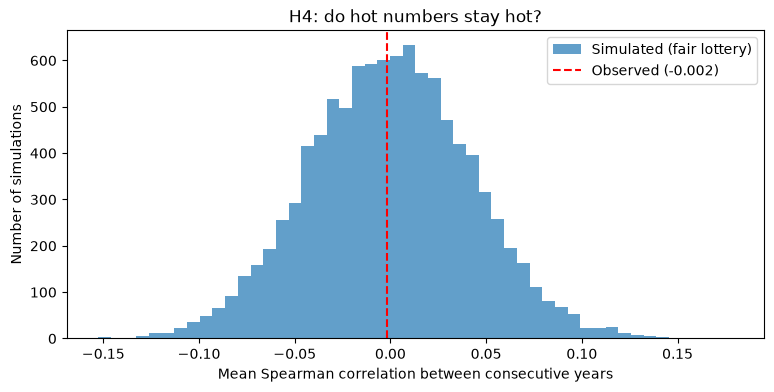

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(sim_rho, bins=50, alpha=0.7, label="Simulated (fair lottery)")
ax.axvline(observed_rho, color="red", linestyle="--", label=f"Observed ({observed_rho:.3f})")

ax.set_xlabel("Mean Spearman correlation between consecutive years")
ax.set_ylabel("Number of simulations")
ax.set_title("H4: do hot numbers stay hot?")
ax.legend()

plt.show()

**Result**
- The year-to-year correlations of the number rankings range from −0.20 to +0.26, with a mean of −0.002.
- In a simulated fair lottery, the same statistic has a mean of 0.000 and a standard deviation of 0.042, and 95% of simulated values fall between −0.083 and +0.084. The observed value sits in the center of this range.
- Monte Carlo p-value = 0.96, well above α = 0.05, so I fail to reject H0.
- **Conclusion for H4:** there is no evidence that numbers that are frequent in one year stay frequent in the next. The individual year-to-year correlations (some positive, some negative) look like noise, as expected when each year contains only about 100 draws.

## H5 – Is a number "due" after a long absence?

- **H0:** a number's chance to appear does not depend on how long it has been absent. The gap between two consecutive appearances of a number (measured in draws) follows a geometric distribution with p = 6/37.
- **H1:** the gap distribution differs from the geometric one (e.g. numbers appear sooner or later than chance would predict after an absence).
- **Method:** chi-square goodness-of-fit test on all gaps of all 37 numbers pooled together (gaps of 1 to 20 draws, and 21 or more merged into one group). The p-value is confirmed with a Monte Carlo simulation, because the gaps of different numbers are linked: exactly 6 numbers are drawn each time.
- **Note:** the time before a number's first appearance and after its last appearance is not counted, because those gaps are cut off by the start and end of the data.

In [15]:
MAX_GAP = 21  # gaps of 21 draws or more are merged into one group

def gap_counts(drawn_flags):
    # for every number, the distances (in draws) between consecutive appearances
    cols, rows = np.nonzero(drawn_flags.T)  # sorted by number, then by draw
    same_number = cols[1:] == cols[:-1]
    gaps = np.diff(rows)[same_number]
    return np.bincount(np.minimum(gaps, MAX_GAP), minlength=MAX_GAP + 1)[1:]

flags = np.zeros((n_draws, 37), dtype=bool)
flags[np.arange(n_draws)[:, None], df[num_cols].to_numpy() - 1] = True

obs_gaps = gap_counts(flags)
n_gaps = obs_gaps.sum()

# if there is no memory, the gap follows a geometric distribution with p = 6/37
p_hit = 6 / 37
k = np.arange(1, MAX_GAP)
exp_gaps = np.append(p_hit * (1 - p_hit) ** (k - 1), (1 - p_hit) ** (MAX_GAP - 1)) * n_gaps

chi2_gaps, p_gaps = stats.chisquare(obs_gaps, f_exp=exp_gaps)

print(f"Number of gaps: {n_gaps}")
print(f"Chi-square statistic: {chi2_gaps:.2f}")
print(f"Degrees of freedom: {len(obs_gaps) - 1}")
print(f"p-value: {p_gaps:.3f}")
print("Reject H0" if p_gaps < ALPHA else "Fail to reject H0")

Number of gaps: 10427
Chi-square statistic: 14.28
Degrees of freedom: 20
p-value: 0.816
Fail to reject H0


In [16]:
rng = np.random.default_rng(42)
n_sims = 10_000
sim_chi2_gaps = np.empty(n_sims)
draw_idx = np.arange(n_draws)[:, None]

for i in range(n_sims):
    drawn = rng.random((n_draws, 37)).argpartition(6, axis=1)[:, :6]
    sim_flags = np.zeros((n_draws, 37), dtype=bool)
    sim_flags[draw_idx, drawn] = True
    sim_obs = gap_counts(sim_flags)
    sim_chi2_gaps[i] = ((sim_obs - exp_gaps) ** 2 / exp_gaps).sum()

p_gaps_mc = (np.sum(sim_chi2_gaps >= chi2_gaps) + 1) / (n_sims + 1)

print(f"Observed chi-square: {chi2_gaps:.2f}")
print(f"Mean of simulated chi-square: {sim_chi2_gaps.mean():.2f}")
print(f"95th percentile of simulated chi-square: {np.percentile(sim_chi2_gaps, 95):.2f}")
print(f"Monte Carlo p-value: {p_gaps_mc:.3f}")

Observed chi-square: 14.28
Mean of simulated chi-square: 19.19
95th percentile of simulated chi-square: 30.35
Monte Carlo p-value: 0.774


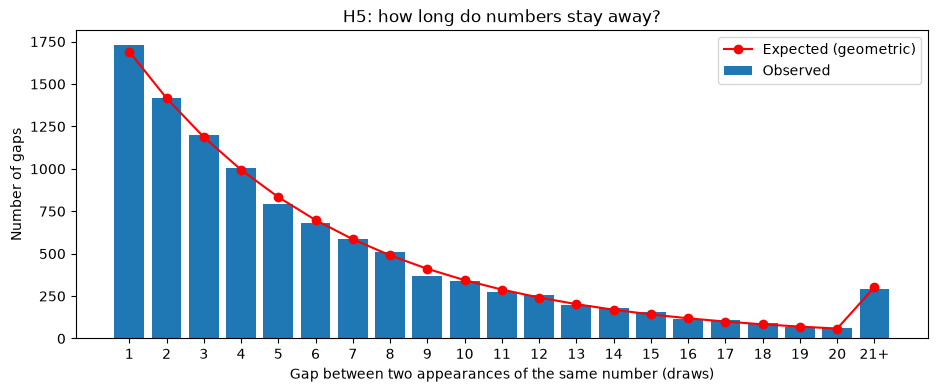

In [17]:
import matplotlib.pyplot as plt

labels = [str(i) for i in range(1, MAX_GAP)] + [f"{MAX_GAP}+"]
x = np.arange(MAX_GAP)

fig, ax = plt.subplots(figsize=(11, 4))

ax.bar(x, obs_gaps, label="Observed")
ax.plot(x, exp_gaps, color="red", marker="o", label="Expected (geometric)")

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlabel("Gap between two appearances of the same number (draws)")
ax.set_ylabel("Number of gaps")
ax.set_title("H5: how long do numbers stay away?")
ax.legend()

plt.show()

**Result**
- The 37 numbers produce 10,427 gaps between appearances. The observed gap distribution follows the geometric curve closely (for example, 1,729 numbers reappeared in the very next draw vs. 1,691 expected).
- Chi-square statistic = 14.28 with 20 degrees of freedom, p = 0.82. The Monte Carlo p-value is 0.77 (simulated chi-square values average 19.2, with a 95th percentile of 30.3), so the result does not depend on the simplifying assumptions of the classic test.
- **Conclusion for H5:** fail to reject H0. In plain terms, a number that has been absent for many draws is no more (and no less) likely to appear next than a number that was just drawn. There is no evidence for "due" numbers.